<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_backends.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc
!pip install qiskit[visualization]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 39.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
Gamma = 0.25
delta_t = 1
g = np.sqrt(Gamma/delta_t)
omega = 1
N = 30
nshots = 1024

simulator_aer = AerSimulator()

# Create simulator with noise from a quantum simulator
service = QiskitRuntimeService(channel="ibm_quantum_platform", token="")
real_backend = service.backend("ibm_kingston")
sim_backend = AerSimulator.from_backend(real_backend)



qiskit_runtime_service._discover_account:WARNING:2026-10-16 22:30:08,867: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-16 22:30:11,737: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-16 22:30:11,739: Using instance: open-instance, plan: open


# Refresh Ancilla

## Standard code

In [ ]:
sz_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.measure(0,0)
    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)
    #job = simualtor_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2.append(-valor)

In [ ]:
sx_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.h(0)
    qc.measure(0,0)

    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)
    #job = simualtor_aer.run(qc,shots = nshots)


    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_2.append(valor)

KeyboardInterrupt: 

In [ ]:
sy_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    transpiled_qc = transpile(qc, backend=sim_backend)
    job = sim_backend.run(transpiled_qc,shots = nshots)
    #job = simualtor_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_2.append(-valor)

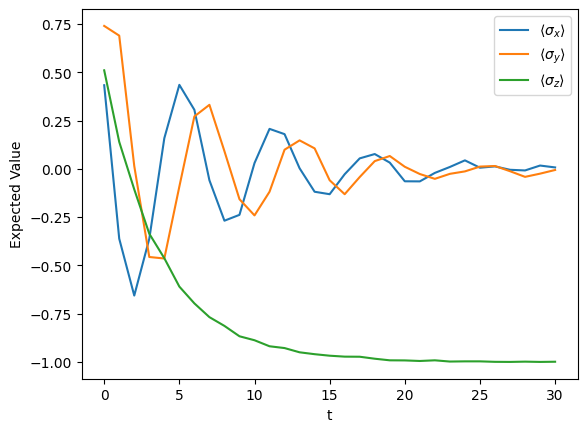

In [ ]:
time = np.arange(N+1) * delta_t
plt.plot(time, sx_2,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()


In [ ]:

datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_nonoise_sxsysz_ns4096.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Swapping orders Rz gate and RxxRyy

In [ ]:
sz_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rz(-omega*delta_t,0)
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.reset(1)
    qc.measure(0,0)
    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2.append(-valor)

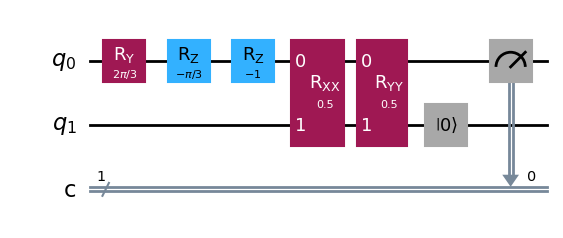

In [ ]:
qc = QuantumCircuit(2,1)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
for i in range(0,1):
    qc.rz(-omega*delta_t,0)
    qc.rxx(g*delta_t,0,1)
    qc.ryy(g*delta_t,0,1)
    qc.reset(1)
qc.measure(0,0)
qc.draw('mpl')

In [ ]:
sx_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rz(-omega*delta_t,0)
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.reset(1)
    qc.h(0)
    qc.measure(0,0)

    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)


    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_2.append(valor)

In [ ]:
sy_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rz(-omega*delta_t,0)
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.reset(1)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_2.append(-valor)

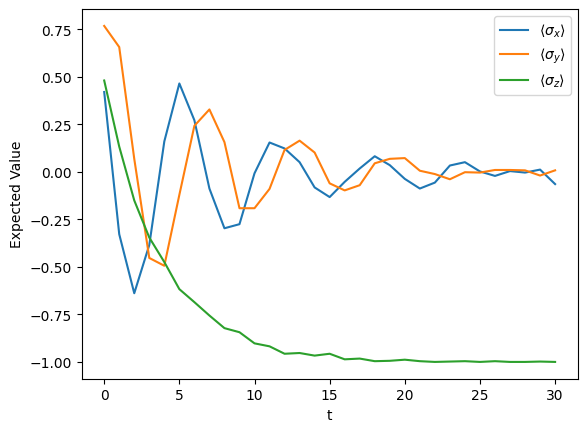

In [ ]:
time = np.arange(N+1) * delta_t
plt.plot(time, sx_2,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()



In [ ]:
datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_nonoise_sxsysz_ns1024_swaptrott.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Adding frequency ancilla

In [ ]:
omega_A = 1

In [ ]:
sz_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rz(-omega_A*delta_t,1)
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.measure(0,0)
    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2.append(-valor)

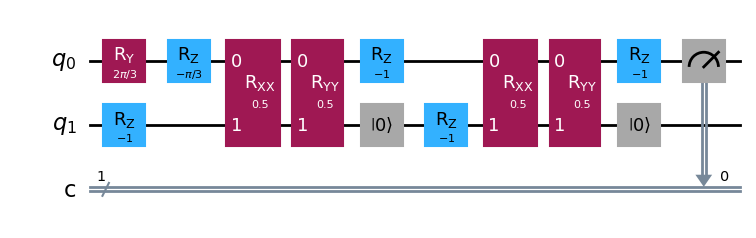

In [ ]:
qc = QuantumCircuit(2,1)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
for i in range(0,2):
  qc.rz(-omega_A*delta_t,1)
  qc.rxx(g*delta_t,0,1)
  qc.ryy(g*delta_t,0,1)
  qc.rz(-omega*delta_t,0)
  qc.reset(1)
qc.measure(0,0)
qc.draw('mpl')

In [ ]:
sx_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
    qc.h(0)
    qc.measure(0,0)

    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)


    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_2.append(valor)

In [ ]:
sy_2 = []
for niter in range(0,N+1):
    qc = QuantumCircuit(2,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_2.append(-valor)

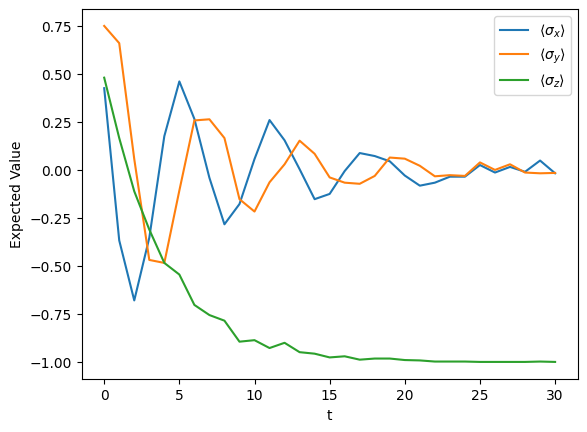

In [ ]:
time = np.arange(N+1) * delta_t
plt.plot(time, sx_2,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()


In [ ]:
datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_nonoise_sxsysz_ns1024_wA_1.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Adding free evolution Hamiltonian

In [ ]:
N_free = 30

In [ ]:
sz_2 = []
for niter in range(0,N + N_free+1):
  qc = QuantumCircuit(2,1)
  qc.ry(np.pi-np.pi/3,0)
  qc.rz(-np.pi/3,0)
  for i in range(0,niter):
    if i<=N:
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
    if (i>N):
      qc.rz(-omega*delta_t,0)
  qc.measure(0,0)
  transpiled_qc = transpile(qc, backend=sim_backend)
  job = sim_backend.run(transpiled_qc,shots = nshots)
  #job = simualtor_aer.run(qc,shots = nshots)
  results = job.result().get_counts()
  valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
  sz_2.append(-valor)

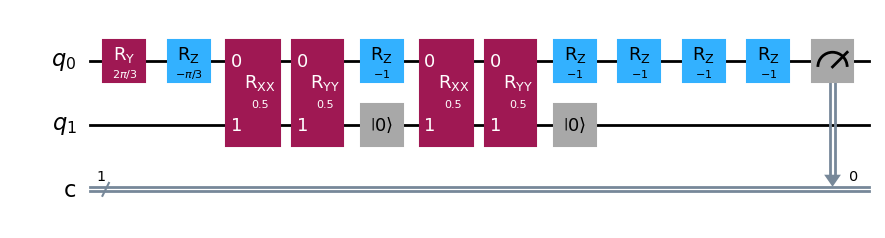

In [ ]:

qc = QuantumCircuit(2,1)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
for i in range(0,5):
  if i<=1:
    qc.rxx(g*delta_t,0,1)
    qc.ryy(g*delta_t,0,1)
    qc.rz(-omega*delta_t,0)
    qc.reset(1)
  if (i>1):
    qc.rz(-omega*delta_t,0)
qc.measure(0,0)
qc.draw('mpl')

In [ ]:
sx_2 = []
for niter in range(0,N+N_free+1):
  qc = QuantumCircuit(2,1)
  qc.ry(np.pi-np.pi/3,0)
  qc.rz(-np.pi/3,0)
  for i in range(0,niter):
    if i<=N:
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
    if (i>N):
      qc.rz(-omega*delta_t,0)
  qc.h(0)
  qc.measure(0,0)

  transpiled_qc = transpile(qc, backend=sim_backend)
  job = sim_backend.run(transpiled_qc,shots = nshots)
  #job = simualtor_aer.run(qc,shots = nshots)


  results = job.result().get_counts()
  valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
  sx_2.append(valor)

In [ ]:
sy_2 = []
for niter in range(0,N + N_free+1):
  qc = QuantumCircuit(2,1)
  qc.ry(np.pi-np.pi/3,0)
  qc.rz(-np.pi/3,0)
  for i in range(0,niter):
    if i<=N:
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
    if (i>N):
      qc.rz(-omega*delta_t,0)
  qc.sdg(0)
  qc.h(0)
  qc.measure(0,0)
  transpiled_qc = transpile(qc, backend=sim_backend)
  job = sim_backend.run(transpiled_qc,shots = nshots)
  #job = simualtor_aer.run(qc,shots = nshots)

  results = job.result().get_counts()
  valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
  sy_2.append(-valor)

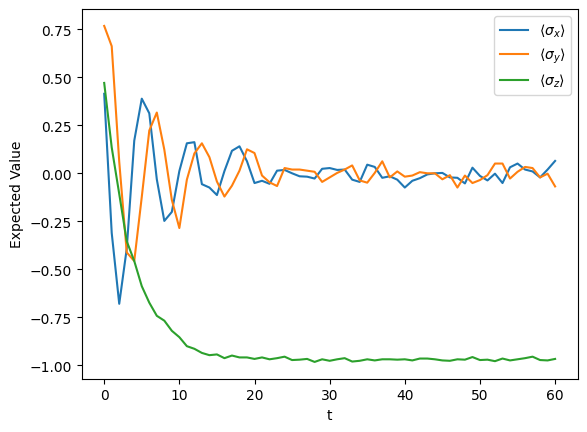

In [ ]:
time = np.arange(N + N_free+1) * delta_t
plt.plot(time, sx_2,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()


In [ ]:
datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "/content/drive/MyDrive/qiskit2_kingston_sxsysz_ns1024_Nfree_30.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Mixed reset-fresh ancillas

Set a number of ancillas (5 in this case) and reset them when necessary

In [ ]:
sz_4 = []
for niter in range(0,N+1):
  if niter <=5:
    qc = QuantumCircuit(niter+1,1)
  else:
    qc = QuantumCircuit(6,1)
  qc.ry(np.pi-np.pi/3,0)
  qc.rz(-np.pi/3,0)
  for i in range(1,niter+1):
    if i<6:
      j=i
    else:
      j = i%5
      if j ==0:
        j = 5
      qc.reset(j)
    qc.rxx(g*delta_t,0,j)
    qc.ryy(g*delta_t,0,j)
    qc.rz(-omega*delta_t,0)
  qc.measure(0,0)
  transpiled_qc = transpile(qc, backend=sim_backend)
  job = sim_backend.run(transpiled_qc,shots = nshots)
  #job = simualtor_aer.run(qc,shots = nshots)
  results = job.result().get_counts()
  valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
  sz_4.append(-valor)

In [ ]:
sx_4 = []
for niter in range(0,N+1):
  if niter <=5:
    qc = QuantumCircuit(niter+1,1)
  else:
    qc = QuantumCircuit(6,1)
  qc.ry(np.pi-np.pi/3,0)
  qc.rz(-np.pi/3,0)
  for i in range(1,niter+1):
    if i<6:
      j=i
    else:
      j = i%5
      if j ==0:
        j = 5
      qc.reset(j)
    qc.rxx(g*delta_t,0,j)
    qc.ryy(g*delta_t,0,j)
    qc.rz(-omega*delta_t,0)
  qc.h(0)
  qc.measure(0,0)

  transpiled_qc = transpile(qc, backend=sim_backend)
  job = sim_backend.run(transpiled_qc,shots = nshots)
  #job = simualtor_aer.run(qc,shots = nshots)
  results = job.result().get_counts()
  valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
  sx_4.append(valor)

In [ ]:
sy_4 = []
for niter in range(0,N+1):
  if niter <=5:
    qc = QuantumCircuit(niter+1,1)
  else:
    qc = QuantumCircuit(6,1)
  qc.ry(np.pi-np.pi/3,0)
  qc.rz(-np.pi/3,0)
  for i in range(1,niter+1):
    if i<6:
      j=i
    else:
      j = i%5
      if j ==0:
        j = 5
      qc.reset(j)
    qc.rxx(g*delta_t,0,j)
    qc.ryy(g*delta_t,0,j)
    qc.rz(-omega*delta_t,0)
  qc.sdg(0)
  qc.h(0)
  qc.measure(0,0)
  transpiled_qc = transpile(qc, backend=sim_backend)
  job = sim_backend.run(transpiled_qc,shots = nshots)
  #job = simualtor_aer.run(qc,shots = nshots)
  results = job.result().get_counts()
  valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
  sy_4.append(-valor)

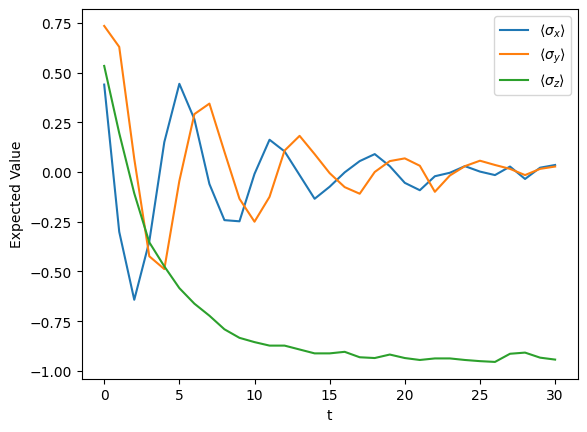

In [ ]:
time = np.arange(N+1) * delta_t
plt.plot(time, sx_4,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_4,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_4,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()

datos = np.column_stack((time, sx_4, sy_4, sz_4))

# N ancillas

In [ ]:
sz_3 = []
for niter in range(0,N):
  print(niter)
  i_system = int(niter/2)
  qc = QuantumCircuit(niter+1,1)
  qc.ry(np.pi-np.pi/3,i_system)
  qc.rz(-np.pi/3,i_system)
  for i in range(0,niter+1):
    if i != i_system:
      qc.rxx(g*delta_t,i_system,i)
      qc.ryy(g*delta_t,i_system,i)
      qc.rz(-omega*delta_t,i_system)
  qc.measure(i_system,0)
  #transpiled_qc = transpile(qc, backend=sim_backend)
  #job = sim_backend.run(transpiled_qc,shots = nshots)
  job = simualtor_aer.run(qc,shots = nshots)
  results = job.result().get_counts()
  valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
  sz_3.append(-valor)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25


KeyboardInterrupt: 

In [ ]:
sx_3 = []
for niter in range(0,N):
    qc = QuantumCircuit(N+1,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(1,niter+1):
        qc.rxx(g*delta_t,0,i)
        qc.ryy(g*delta_t,0,i)
        qc.rz(-omega*delta_t,0)
    qc.h(0)
    qc.measure(0,0)

    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = nshots)
    job = simualtor_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_3.append(valor)

In [ ]:
sy_3 = []
for niter in range(0,N):
    qc = QuantumCircuit(N+1,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(1,niter+1):
        qc.rxx(g*delta_t,0,i)
        qc.ryy(g*delta_t,0,i)
        qc.rz(-omega*delta_t,0)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    #transpiled_qc = transpile(qc, backend=sim_backend)
    #job = sim_backend.run(transpiled_qc,shots = shots)
    job = simualtor_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_3.append(-valor)

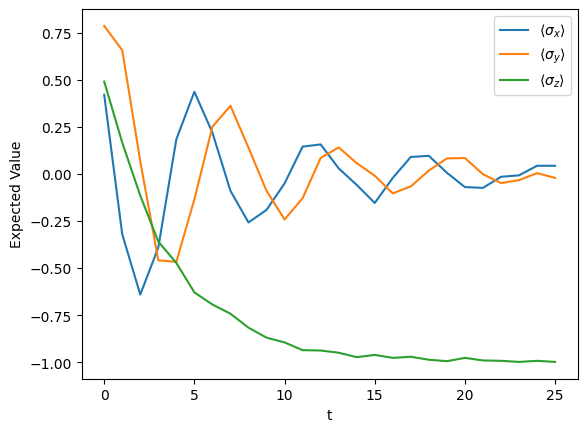

In [ ]:
time = np.arange(N) * delta_t
plt.plot(time, sx_3,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_3,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_3,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()
datos = np.column_stack((time, sx_3, sy_3, sz_3))